# 03 - Clustering

Segments `Mall_Customers.csv` using K-Means, Agglomerative Clustering, and DBSCAN on `Annual Income (k$)` and `Spending Score (1-100)`.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

from src import config
from src.clustering import run_clustering
from src.visualization import plot_customer_clusters, plot_elbow_and_silhouette

result = run_clustering()
result['metrics_df']

,model,n_clusters,n_noise_points,silhouette_score,chosen_k
0,KMeans,5,0,0.554657,5.0
1,Agglomerative,5,0,0.553809,5.0
2,DBSCAN,2,11,0.396284,NaN


In [2]:
print(f"Best K (by silhouette score): {result['best_k']}")
print(f"DBSCAN eps={result['dbscan_eps']:.3f}, min_samples={result['dbscan_min_samples']}")
result['segment_profiles']

Best K (by silhouette score): 5
DBSCAN eps=0.468, min_samples=5


,Annual Income (k$),Spending Score (1-100),Age,count
KMeans_cluster,,,,
0,55.3,49.5,42.7,81
1,86.5,82.1,32.7,39
2,25.7,79.4,25.3,22
3,88.2,17.1,41.1,35
4,26.3,20.9,45.2,23


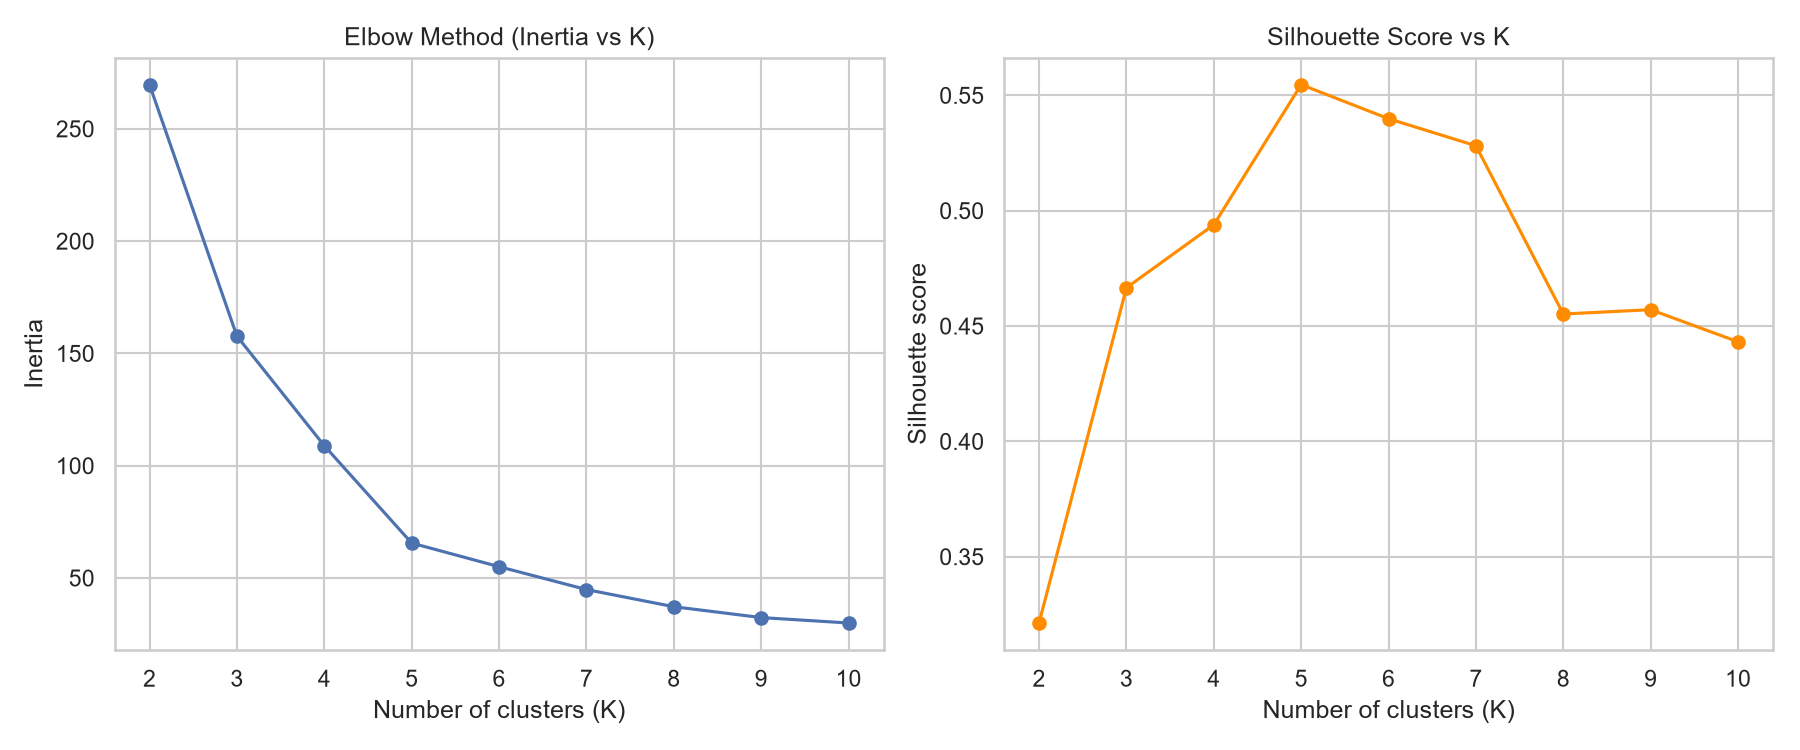

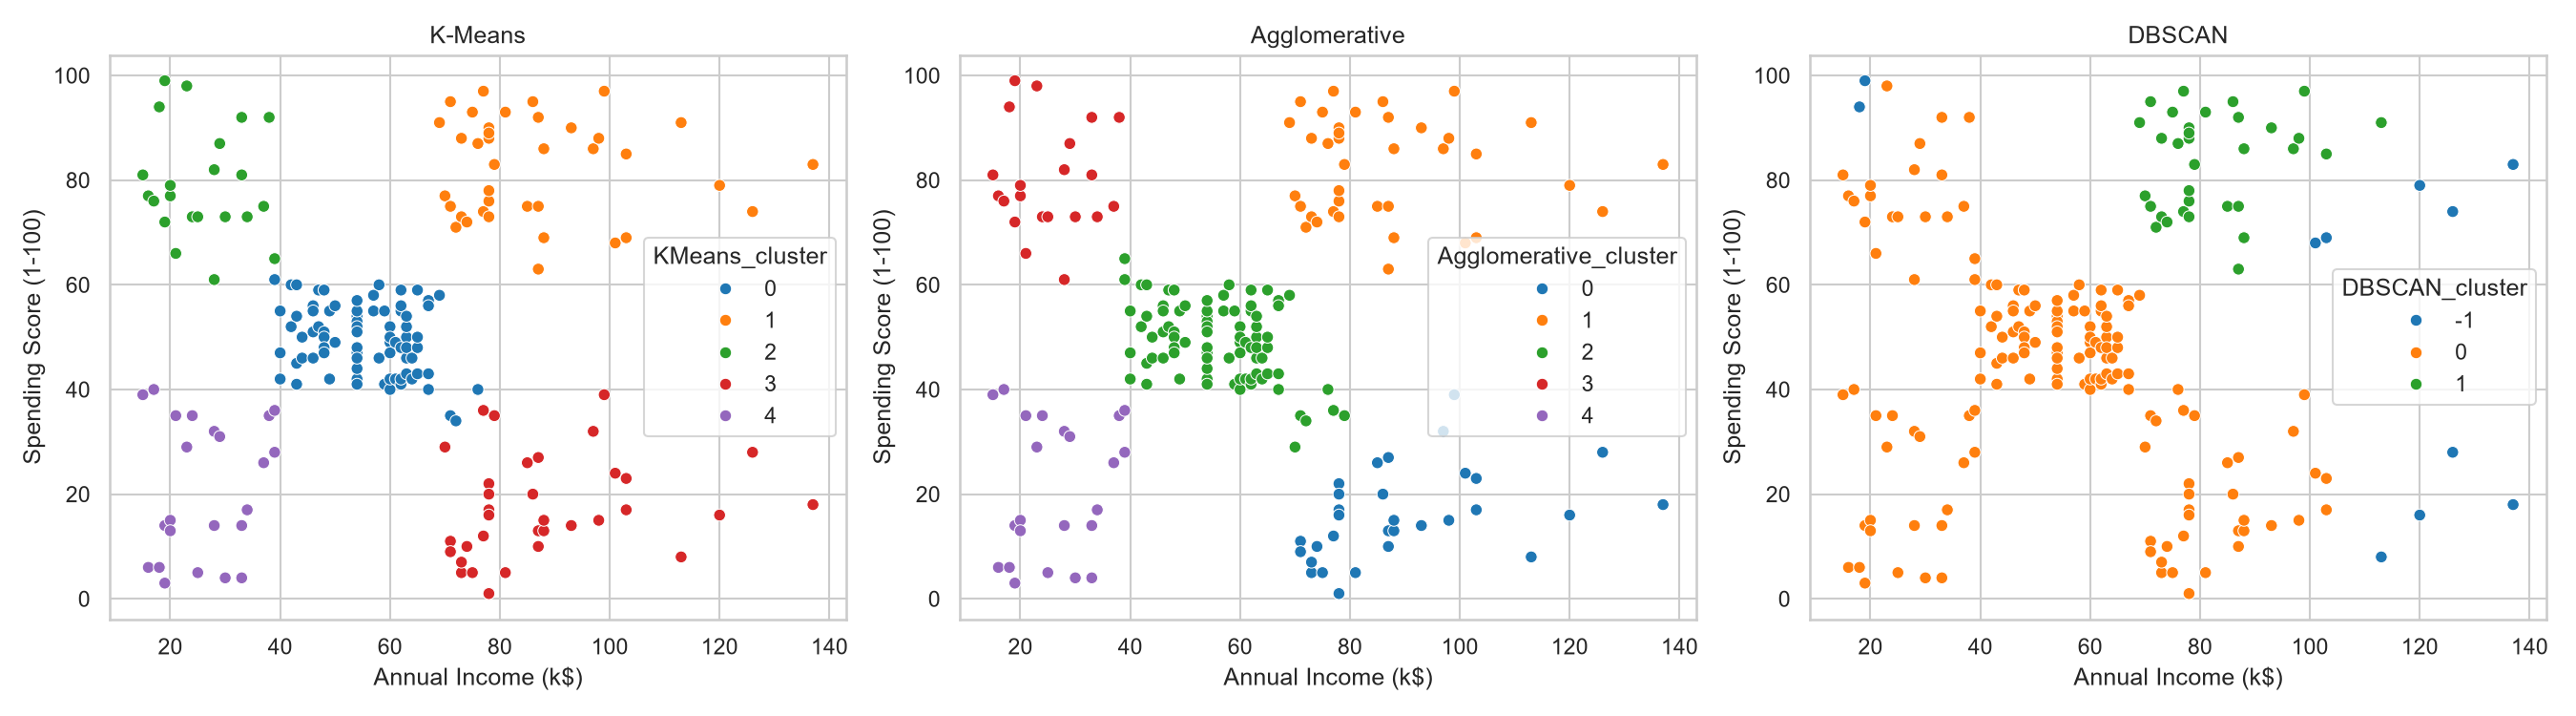

In [3]:
plot_elbow_and_silhouette(result['k_values'], result['inertias'], result['silhouettes'], config.PLOTS_DIR / 'clustering_elbow.png')
plot_customer_clusters(
    result['assignments_df'], 'Annual Income (k$)', 'Spending Score (1-100)',
    {'K-Means': 'KMeans_cluster', 'Agglomerative': 'Agglomerative_cluster', 'DBSCAN': 'DBSCAN_cluster'},
    config.PLOTS_DIR / 'customer_clusters.png'
)

from IPython.display import Image, display
display(Image(filename=str(config.PLOTS_DIR / 'clustering_elbow.png')))
display(Image(filename=str(config.PLOTS_DIR / 'customer_clusters.png')))

In [4]:
result['assignments_df'].head()

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100),KMeans_cluster,Agglomerative_cluster,DBSCAN_cluster
0,1,Male,19,15,39,4,4,0
1,2,Male,21,15,81,2,3,0
2,3,Female,20,16,6,4,4,0
3,4,Female,23,16,77,2,3,0
4,5,Female,31,17,40,4,4,0
